In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from wiki_forecast.evaluation import cached
from wiki_forecast.features import FEATURES, FEATURES_PEAK, build_dataset, to_log_wide
from wiki_forecast.global_model import global_backtest, quantile_params

pd.set_option("display.max_rows", 200)

df = pd.read_parquet("../data/raw/pageviews.parquet")
log_wide = to_log_wide(df)

HORIZONS = range(1, 29)
RESULTS_DIR = Path("../data/results")
FEATURES_MAIN = [*FEATURES, "season_corr", "article", *FEATURES_PEAK]

classical = pd.read_parquet(RESULTS_DIR / "classical_oktoberfest.parquet")
cutoffs = pd.DatetimeIndex(sorted(classical["cutoff"].unique()))

global_train = build_dataset(
    log_wide, pd.date_range("2018-01-01", log_wide.index[-1], freq="14D"), HORIZONS
)

In [2]:
q50 = pd.read_parquet(RESULTS_DIR / "lgbm_global_corr_id_peak.parquet")

q10, q90 = (
    cached(
        RESULTS_DIR / f"lgbm_main_peak_q{int(alpha * 100)}.parquet",
        lambda alpha=alpha: global_backtest(
            log_wide, global_train, cutoffs, HORIZONS, f"q{int(alpha * 100)}",
            features=FEATURES_MAIN, params=quantile_params(alpha),
        ),
    )
    for alpha in (0.1, 0.9)
)

q10: trained on 1,730,216 rows up to 2022-08-10 in 30s
q10: trained on 1,913,260 rows up to 2023-01-25 in 29s
q10: trained on 2,097,674 rows up to 2023-07-12 in 32s
q10: trained on 2,282,882 rows up to 2023-12-27 in 43s
q10: trained on 2,468,690 rows up to 2024-06-12 in 41s
q10: trained on 2,654,498 rows up to 2024-11-27 in 52s
q10: trained on 2,840,306 rows up to 2025-05-14 in 46s
q10: trained on 3,026,114 rows up to 2025-10-29 in 47s
q10: trained on 3,211,922 rows up to 2026-04-15 in 54s
q10: trained on 3,397,730 rows up to 2026-09-30 in 59s
q90: trained on 1,730,216 rows up to 2022-08-10 in 28s
q90: trained on 1,913,260 rows up to 2023-01-25 in 31s
q90: trained on 2,097,674 rows up to 2023-07-12 in 32s
q90: trained on 2,282,882 rows up to 2023-12-27 in 39s
q90: trained on 2,468,690 rows up to 2024-06-12 in 37s
q90: trained on 2,654,498 rows up to 2024-11-27 in 37s
q90: trained on 2,840,306 rows up to 2025-05-14 in 46s
q90: trained on 3,026,114 rows up to 2025-10-29 in 47s
q90: train

In [3]:
keys = ["article", "cutoff", "date"]
iv = (
    q50.rename(columns={"pred": "q50"})
    .merge(q10[[*keys, "pred"]].rename(columns={"pred": "q10"}), on=keys)
    .merge(q90[[*keys, "pred"]].rename(columns={"pred": "q90"}), on=keys)
)

crossed = (iv["q10"] > iv["q50"]) | (iv["q50"] > iv["q90"])
print(f"Rows with crossed quantiles: {crossed.mean():.2%}")

iv[["q10", "q50", "q90"]] = np.sort(iv[["q10", "q50", "q90"]].to_numpy(), axis=1)

iv["inside"] = iv["actual"].between(iv["q10"], iv["q90"])
iv["below"] = iv["actual"] < iv["q10"]
iv["above"] = iv["actual"] > iv["q90"]
iv["width"] = np.log1p(iv["q90"]) - np.log1p(iv["q10"])
iv["year"] = iv["date"].dt.year

Rows with crossed quantiles: 0.46%


In [4]:
def calibration(g: pd.DataFrame) -> pd.Series:
    return pd.Series({
        "coverage": g["inside"].mean(),
        "below_q10": g["below"].mean(),
        "above_q90": g["above"].mean(),
        "median_width": g["width"].median(),
    })

display(calibration(iv).to_frame("all articles").T)
iv.groupby("year").apply(calibration, include_groups=False)

,coverage,below_q10,above_q90,median_width
all articles,0.72462,0.141382,0.133998,0.520457


,coverage,below_q10,above_q90,median_width
year,,,,
2022,0.719912,0.110691,0.169397,0.515661
2023,0.740362,0.099448,0.160190,0.521931
2024,0.713357,0.153238,0.133405,0.519687
2025,0.723570,0.158869,0.117561,0.518789
2026,0.722811,0.170667,0.106523,0.524243


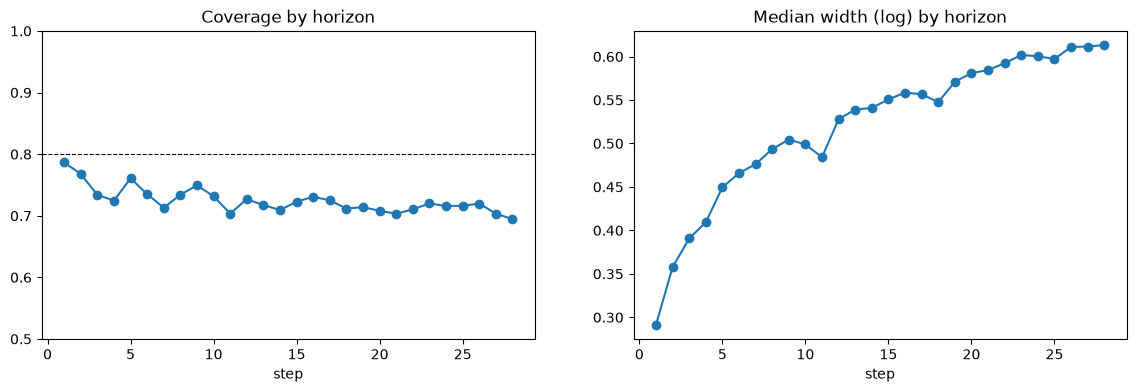

In [5]:
by_step = iv.groupby("step").apply(calibration, include_groups=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
by_step["coverage"].plot(ax=axes[0], marker="o", title="Coverage by horizon")
axes[0].axhline(0.8, color="black", ls="--", lw=0.8)
axes[0].set_ylim(0.5, 1)
by_step["median_width"].plot(ax=axes[1], marker="o", title="Median width (log) by horizon")
plt.show()

In [6]:
seasonal = [
    "Oktoberfest", "List_of_Super_Bowl_champions", "Martin_Luther_King_Jr.",
    "National_Football_League", "Mariah_Carey", "Macaulay_Culkin",
    "George_Washington", "List_of_UFC_events",
]
display(iv[iv["article"].isin(seasonal)].groupby("article").apply(calibration, include_groups=False))

okt_festival = iv[(iv["article"] == "Oktoberfest") & iv["date"].dt.month.isin([9, 10])]
calibration(okt_festival).to_frame("Oktoberfest, Sep–Oct").T

,coverage,below_q10,above_q90,median_width
article,,,,
George_Washington,0.733766,0.141558,0.124675,0.285819
List_of_Super_Bowl_champions,0.736364,0.051299,0.212338,0.622411
List_of_UFC_events,0.803247,0.059091,0.137662,0.436191
Macaulay_Culkin,0.711039,0.140260,0.148701,0.684841
Mariah_Carey,0.754545,0.149351,0.096104,0.591748
Martin_Luther_King_Jr.,0.744805,0.195455,0.059740,0.429505
National_Football_League,0.714935,0.098701,0.186364,0.400396
Oktoberfest,0.757792,0.138961,0.103247,0.330164


,coverage,below_q10,above_q90,median_width
"Oktoberfest, Sep–Oct",0.741722,0.10596,0.152318,0.839368


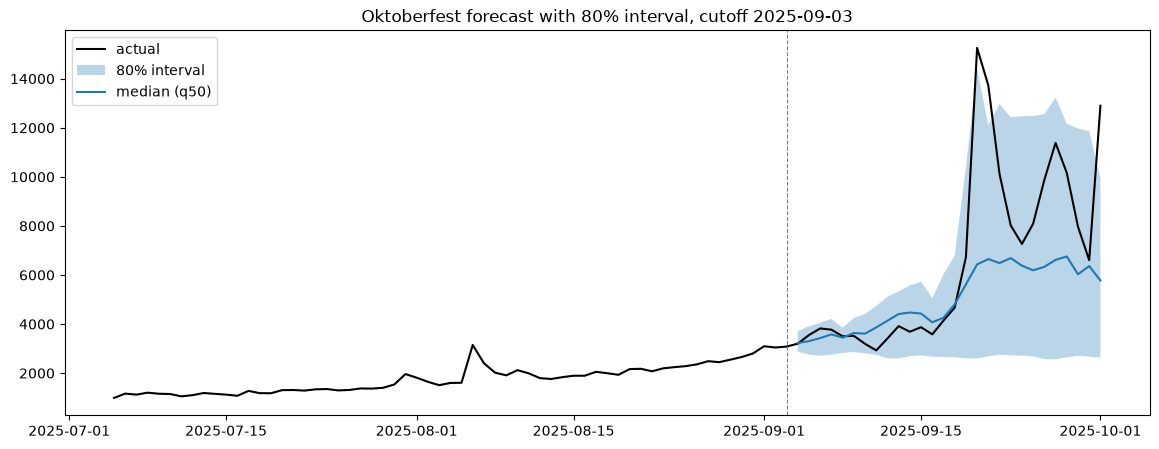

In [7]:
s = np.expm1(log_wide["Oktoberfest"])
c = min(cutoffs, key=lambda x: abs(x - pd.Timestamp("2025-09-10")))
fold = iv[(iv["article"] == "Oktoberfest") & (iv["cutoff"] == c)]

fig, ax = plt.subplots(figsize=(14, 5))
seg = s[c - pd.Timedelta(days=60) : fold["date"].max()]
ax.plot(seg.index, seg.to_numpy(), color="black", lw=1.5, label="actual")
ax.fill_between(fold["date"], fold["q10"], fold["q90"], alpha=0.3, label="80% interval")
ax.plot(fold["date"], fold["q50"], lw=1.5, label="median (q50)")
ax.axvline(c, color="gray", ls="--", lw=0.8)
ax.set_title(f"Oktoberfest forecast with 80% interval, cutoff {c.date()}")
ax.legend()
plt.show()

In [8]:
def calibration(g: pd.DataFrame, lo: str = "q10", hi: str = "q90") -> pd.Series:
    inside = g["actual"].between(g[lo], g[hi])
    return pd.Series({
        "coverage": inside.mean(),
        "below": (g["actual"] < g[lo]).mean(),
        "above": (g["actual"] > g[hi]).mean(),
        "median_width": (np.log1p(g[hi]) - np.log1p(g[lo])).median(),
    })

In [9]:
WINDOW = 12     # calibrate on the latest 12 past folds (~11 months)
MIN_FOLDS = 6   # skip the first folds, which have too little history

iv["score"] = np.maximum(
    np.log1p(iv["q10"]) - np.log1p(iv["actual"]),
    np.log1p(iv["actual"]) - np.log1p(iv["q90"]),
)

fold_list = sorted(iv["cutoff"].unique())
parts = []
for i, c in enumerate(fold_list):
    if i < MIN_FOLDS:
        continue
    past = iv[iv["cutoff"].isin(fold_list[max(0, i - WINDOW) : i])]  # only earlier folds
    q_by_step = past.groupby("step")["score"].quantile(0.8)

    current = iv[iv["cutoff"] == c].copy()
    adjust = current["step"].map(q_by_step).to_numpy()
    current["q10_cal"] = np.expm1(np.log1p(current["q10"]) - adjust)
    current["q90_cal"] = np.expm1(np.log1p(current["q90"]) + adjust)
    parts.append(current)

cal = pd.concat(parts, ignore_index=True)
print(f"Calibrated {cal['cutoff'].nunique()} folds")

Calibrated 49 folds


,coverage,below,above,median_width
raw,0.724618,0.145439,0.129943,0.519925
calibrated,0.801644,0.089216,0.109140,0.611378


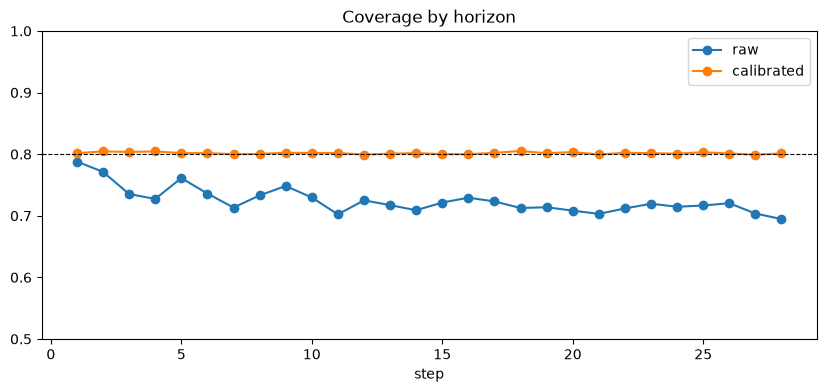

,coverage,below,above,median_width
year,,,,
2023,0.805398,0.060707,0.133895,0.613269
2024,0.793195,0.094714,0.112091,0.612849
2025,0.809641,0.092467,0.097892,0.615235
2026,0.798003,0.110620,0.091377,0.602510


In [10]:
display(pd.DataFrame({
    "raw": calibration(cal),
    "calibrated": calibration(cal, "q10_cal", "q90_cal"),
}).T)

by_step_cmp = pd.DataFrame({
    "raw": cal.groupby("step").apply(calibration, include_groups=False)["coverage"],
    "calibrated": cal.groupby("step").apply(
        calibration, "q10_cal", "q90_cal", include_groups=False
    )["coverage"],
})
ax = by_step_cmp.plot(marker="o", figsize=(10, 4), title="Coverage by horizon")
ax.axhline(0.8, color="black", ls="--", lw=0.8)
ax.set_ylim(0.5, 1)
plt.show()

cal["year"] = cal["date"].dt.year
cal.groupby("year").apply(calibration, "q10_cal", "q90_cal", include_groups=False)

,coverage,below,above,median_width
raw,0.796680,0.132780,0.070539,0.915953
calibrated,0.817427,0.124481,0.058091,1.030296


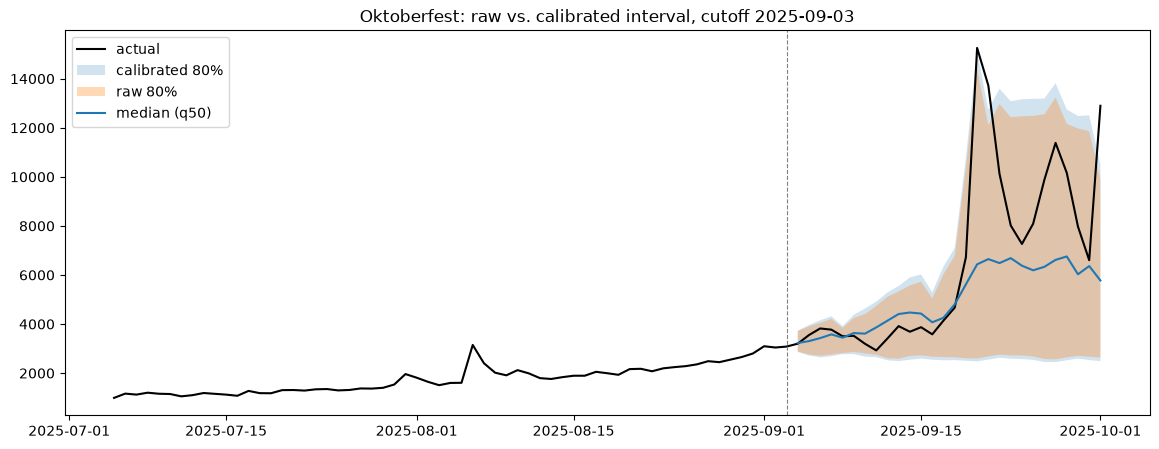

In [11]:
okt_fest = cal[(cal["article"] == "Oktoberfest") & cal["date"].dt.month.isin([9, 10])]
display(pd.DataFrame({
    "raw": calibration(okt_fest),
    "calibrated": calibration(okt_fest, "q10_cal", "q90_cal"),
}).T)

c = min(fold_list, key=lambda x: abs(x - pd.Timestamp("2025-09-10")))
fold = cal[(cal["article"] == "Oktoberfest") & (cal["cutoff"] == c)]
seg = s[c - pd.Timedelta(days=60) : fold["date"].max()]

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(seg.index, seg.to_numpy(), color="black", lw=1.5, label="actual")
ax.fill_between(fold["date"], fold["q10_cal"], fold["q90_cal"], alpha=0.2, label="calibrated 80%")
ax.fill_between(fold["date"], fold["q10"], fold["q90"], alpha=0.3, label="raw 80%")
ax.plot(fold["date"], fold["q50"], lw=1.5, label="median (q50)")
ax.axvline(c, color="gray", ls="--", lw=0.8)
ax.set_title(f"Oktoberfest: raw vs. calibrated interval, cutoff {c.date()}")
ax.legend()
plt.show()

## Findings

**Model:** production global LightGBM (base + season_corr + article ID + sharp seasonal hints).
q50 = the L1 model; q10 / q90 trained with the quantile (pinball) objective.

**Raw quantile intervals (q10–q90, all 55 folds)**
- Crossed quantiles in 0.46% of rows, fixed by sorting.
- Coverage 72.5% instead of 80%; misses on both sides (14.1% below q10, 13.4% above q90):
  the model is overconfident.
- Width grows with the horizon (log width 0.29 → 0.61, i.e. q90/q10 from 1.34 to 1.84),
  but coverage still falls from 79% (day 1) to 70% (day 28).
- Miss direction follows drift: 2022 mostly above (17%, post-COVID rebound),
  2026 mostly below (17%, falling Wikipedia traffic).
- Seasonal articles: Super Bowl (21%) and NFL (19%) still often above q90.
- Oktoberfest festival: 74.2% covered over all folds (69.2% with the previous model);
  the 2022 festival, after two cancelled years, was covered only about half the time.
  The sharp seasonal hints let q90 reach ~14,000 on opening day (actual 15,300),
  even though the median stays low.

**Rolling conformal calibration (per horizon, last 12 past folds only, folds 7–55)**

| | Coverage | Below | Above | Median width |
|---|---|---|---|---|
| Raw | 72.5% | 14.5% | 13.0% | 0.52 |
| Calibrated | 80.2% | 8.9% | 10.9% | 0.61 |

- 80% coverage restored at every horizon and in every year (79.3–81.0%), at the cost of
  intervals ~10% wider.
- The rolling window adapts to drift, using only past data (no leakage).
- Oktoberfest festival (folds 7–55, i.e. excluding the 2022 festival): 79.7% raw →
  81.7% calibrated (previous model on the same folds: 71.8% → 75.5%). The sharp seasonal
  hints, not the calibration, closed most of the gap.
- Calibration fixes the overall size of the uncertainty, not the model's blind spots.
- Possible extension: asymmetric correction (2023 is still lopsided: 6% below, 13% above).